In [1]:
import numpy as np
import matplotlib.pyplot as plt

from dataclasses import dataclass
from enum import Enum

In [2]:
def normalize_quaternion(q: np.ndarray) -> np.ndarray:
    """
    Normalize a quaternion.

    Args:
        q: A numpy array of shape (4,) representing the quaternion [x, y, z, w].

    Returns:
        A numpy array of shape (4,) representing the normalized quaternion.
    """
    q = np.asarray(q, dtype=float).reshape(4)

    norm = np.linalg.norm(q)
    if norm == 0:
        raise ValueError("Quaternion has zero length")
    
    return q / norm

class CameraFrameConvention(Enum):
    """
    Coordinate-frame convention used by the camera projection model.

    OPTICAL_FRAME:
        +x points right in the image
        +y points down in the image
        +z points forward along the optical axis

        Projection:
            u = fx * (x / z) + cx
            v = fy * (y / z) + cy
    """
    OPTICAL_FRAME = "optical_frame"

@dataclass
class CameraIntrinsics:
    width_px: int
    height_px: int
    fx: float
    fy: float
    cx: float | None = None
    cy: float | None = None

    @property
    def principal_point(self) -> tuple[float, float]:
        cx = self.cx if self.cx is not None else self.width_px / 2.0
        cy = self.cy if self.cy is not None else self.height_px / 2.0
        return cx, cy
    
    @property
    def horizontal_fov(self) -> float:
        return np.rad2deg(2 * np.arctan(self.width_px / (2 * self.fx)))
    
    @property
    def vertical_fov(self) -> float:
        return np.rad2deg(2 * np.arctan(self.height_px / (2 * self.fy)))
    
    @property
    def K(self) -> np.ndarray:
        # Camera intrinsic matrix
        cx, cy = self.principal_point

        K = np.array([[self.fx, 0, cx],
                      [0, self.fy, cy],
                      [0, 0, 1]], dtype=float)
        return K
    
@dataclass
class CameraExtrinsics:
    """
    Pose of the camera optical frame in the world frame.

    Camera optical frame convention:
        +x right in the image
        +y down in the image
        +z forward along the optical axis

    Orientation:
        Quaternion [x, y, z, w] representing the rotation from camera optical frame to world frame.
    """

    position: np.ndarray 
    orientation: np.ndarray # quaternion [x, y, z, w], camera optical frame to world frame
    

    @property
    def R_camera_to_world(self) -> np.ndarray:
        # Convert quaternion to rotation matrix
        q = normalize_quaternion(self.orientation)
        
        x, y, z, w = q

        R = np.array([
            [1 - 2*(y**2 + z**2), 2*(x*y - z*w), 2*(x*z + y*w)],
            [2*(x*y + z*w), 1 - 2*(x**2 + z**2), 2*(y*z - x*w)],
            [2*(x*z - y*w), 2*(y*z + x*w), 1 - 2*(x**2 + y**2)]
        ], dtype=float)
        return R
    
    @property
    def t_camera_to_world(self) -> np.ndarray:
        return np.asarray(self.position, dtype=float).reshape(3)
    
    @property
    def R_world_to_camera(self) -> np.ndarray:
        return self.R_camera_to_world.T
    
    @property
    def t_world_to_camera(self) -> np.ndarray:
        return -self.R_world_to_camera @ self.t_camera_to_world
    
    @property
    def world_to_camera_matrix(self) -> np.ndarray:
        return np.hstack([
            self.R_world_to_camera,
            self.t_world_to_camera.reshape((3, 1)),
        ])
 
    @property
    def camera_to_world_matrix(self) -> np.ndarray:
        return np.vstack([
            np.hstack([
                self.R_camera_to_world,
                self.t_camera_to_world.reshape((3, 1))
            ]),
            np.array([[0.0, 0.0, 0.0, 1.0]])
        ])
    
@dataclass
class CameraNoiseModel:
    pixel_noise_std_u: float
    pixel_noise_std_v: float
    detection_probability: float = 1.0
    discretize: bool = True

    @property
    def measurement_noise_covariance(self) -> np.ndarray:
        return np.diag([
            self.pixel_noise_std_u ** 2,
            self.pixel_noise_std_v ** 2
        ])
    
@dataclass
class Camera:
    """
    Pinhole camera sensor model.

    This class assumes that 'extrinsics' describe the pose of the camera optical frame in the world frame.

    Optical frame convention:
        +x points right in the image
        +y points down in the image
        +z points forward along the optical axis

    The projection model is:
        u = fx * (x / z) + cx
        v = fy * (y / z) + cy

    where [x, y, z] is expressed in the camera optical frame.

    Important:
        Do not pass a ROS/Gazebo camera_link pose directly unless that link frame already follows the optical frame convention. Otherwise, first transform from camera_link to camera_optical_frame.
    """

    name: str
    frame_id: str
    intrinsics: CameraIntrinsics
    extrinsics: CameraExtrinsics
    noise_model: CameraNoiseModel
    near_clip: float = 0.1
    far_clip: float = np.inf
    frame_convention: CameraFrameConvention = CameraFrameConvention.OPTICAL_FRAME

    def world_to_camera(self, point_world: np.ndarray) -> np.ndarray:
        """
        Transform a world-frame point into the camera optical frame.

        Camera optical frame convention:
            +x points right in the image
            +y points down in the image
            +z points forward along the optical axis

        Args:
            point_world:
                3D point expressed in world frame.
        
        Returns:
            3D point expressed in the camera optical frame.
            A visible point in front of the camera should have z > 0.
        """
        point_world = np.asarray(point_world, dtype=float).reshape(3)

        R_wc = self.extrinsics.R_world_to_camera
        t_wc = self.extrinsics.t_world_to_camera

        return R_wc @ point_world + t_wc
    
    def project_camera_point(self, point_camera: np.ndarray) -> tuple[float, float] | None:
        if self.frame_convention != CameraFrameConvention.OPTICAL_FRAME:
            raise NotImplementedError(
                f"Projection for frame convention {self.frame_convention} is not implemented."
            )

        x, y, z = np.asarray(point_camera, dtype=float).reshape(3)

        if not (self.near_clip <= z <= self.far_clip):
            return None
        
        cx, cy = self.intrinsics.principal_point

        u = self.intrinsics.fx * (x / z) + cx
        v = self.intrinsics.fy * (y / z) + cy

        if not (0 <= u < self.intrinsics.width_px and 0 <= v < self.intrinsics.height_px):
            return None

        return float(u), float(v)
    
    def measure(
            self,
            point_world: np.ndarray,
            stamp: float,
            rng: np.random.Generator | None = None
    ) -> "CameraMeasurement | None":
        point_camera = self.world_to_camera(point_world)
        projected = self.project_camera_point(point_camera)

        if projected is None:
            return None

        if rng is None:
            rng = np.random.default_rng()

        # add noise using the covariance matrix
        noise = rng.multivariate_normal(
            mean=[0, 0],
            cov=self.noise_model.measurement_noise_covariance
        )

        u_noisy = projected[0] + noise[0]
        v_noisy = projected[1] + noise[1]

        if self.noise_model.discretize:
            u_noisy = np.round(u_noisy)
            v_noisy = np.round(v_noisy)

        u_noisy = float(u_noisy)
        v_noisy = float(v_noisy)

        if not (0 <= u_noisy < self.intrinsics.width_px and 0 <= v_noisy < self.intrinsics.height_px):
            return None
        
        if rng.uniform(0, 1) > self.noise_model.detection_probability:
            return None

        return CameraMeasurement(
            stamp=stamp,
            frame_id=self.frame_id,
            camera_name=self.name,
            u=u_noisy,
            v=v_noisy,
            covariance=self.noise_model.measurement_noise_covariance
        )
    
    def validate_frame_convention(self) -> None:
        """
        Validate that the projection behaves according to the selected camera frame convention.

        For OPTICAL_FRAME:
            [0, 0, z] projects to the principal point (cx, cy).
            Positive x increases u.
            Positive y increases v.
            Negative z is behind the camera.
        """
        if self.frame_convention != CameraFrameConvention.OPTICAL_FRAME:
            raise NotImplementedError(
                f"Validation for frame convention {self.frame_convention} is not implemented."
            )

        cx, cy = self.intrinsics.principal_point
        z = 1.0

        center = self.project_camera_point(np.array([0.0, 0.0, z]))
        right = self.project_camera_point(np.array([0.1, 0.0, z]))
        down = self.project_camera_point(np.array([0.0, 0.1, z]))
        behind = self.project_camera_point(np.array([0.0, 0.0, -z]))

        assert center is not None
        assert right is not None
        assert down is not None
        assert behind is None

        u_center, v_center = center
        u_right, v_right = right
        u_down, v_down = down

        assert np.isclose(u_center, cx)
        assert np.isclose(v_center, cy)

        assert u_right > u_center, "Positive x should increase pixel u."
        assert np.isclose(v_right, v_center)

        assert np.isclose(u_down, u_center)
        assert v_down > v_center, "Positive camera y should increase pixel v."

@dataclass  
class CameraMeasurement:
    """
    A class representing a camera measurement.

    Attributes:
        stamp: The timestamp of the measurement.
        frame_id: The frame ID of the measurement.
        camera_name: The name of the camera that took the measurement.
        u: The pixel x-coordinate of the measurement.
        v: The pixel y-coordinate of the measurement.
        covariance: The covariance matrix of the measurement noise.
    """
    stamp: float
    frame_id: str
    camera_name: str
    u: float # pixel x-coordinate
    v: float # pixel y-coordinate
    covariance: np.ndarray | None = None # covariance matrix of the measurement noise



In [3]:
@dataclass
class SyntheticTrajectory:
    """
    Synthetic target trajectory in the world frame.

    The camera sensor receives only the resulting position p_world(t).
    """
    center: np.ndarray
    radius: float
    altitude: float
    angular_rate: float
    vertical_amplitude: float = 0.0
    vertical_rate: float = 1.0

    def position(self, t: float) -> np.ndarray:
        return np.array([
            self.center[0] + self.radius * np.cos(self.angular_rate * t),
            self.center[1] + self.radius * np.sin(self.angular_rate * t),
            self.center[2] + self.altitude + self.vertical_amplitude * np.sin(self.vertical_rate * t)
        ], dtype=float)
    
@dataclass
class CameraSimulationRecord:
    stamp: float
    point_world: np.ndarray
    point_camera: np.ndarray
    ideal_uv: tuple[float, float] | None
    measurement: CameraMeasurement | None

In [4]:
trajectory = SyntheticTrajectory(
    center=np.array([1.0, 1.0, 0.0]),
    radius=1.0,
    altitude=1.0,
    angular_rate=3.0,
    vertical_amplitude=1.0,
    vertical_rate=0.5
)

In [5]:
def simulate_single_camera(
        camera: Camera,
        trajectory: SyntheticTrajectory,
        t_start: float,
        t_end: float,
        dt: float,
        rng: np.random.Generator | None = None,
) -> list[CameraSimulationRecord]:
    """
    Simulate one camera observing one synthetic target trajectory.

    The returned records include ground truth/debug information.
    The CameraMeasurement itself remains a pure simulated detector output.
    """
    if rng is None:
        rng = np.random.default_rng()

    records: list[CameraSimulationRecord] = []

    times = np.arange(t_start, t_end + 0.5 * dt, dt)

    for t in times:
        point_world = trajectory.position(t)
        point_camera = camera.world_to_camera(point_world)
        ideal_uv = camera.project_camera_point(point_camera)
        measurement = camera.measure(point_world, stamp=float(t), rng=rng)

        records.append(
            CameraSimulationRecord(
                stamp=float(t),
                point_world=point_world,
                point_camera=point_camera,
                ideal_uv=ideal_uv,
                measurement=measurement
            )
        )

    return records

In [6]:
camera = Camera(
    name="cam_0",
    frame_id="cam_0_optical_frame",
    intrinsics=CameraIntrinsics(
        width_px=640,
        height_px=480,
        fx=320.0,
        fy=320.0
    ),
    extrinsics=CameraExtrinsics(
        position=np.array([0.0, 0.0, 0.0]),
        orientation=np.array([0.0, 0.0, 0.0, 1.0])
    ),
    noise_model=CameraNoiseModel(
        pixel_noise_std_u=1.0,
        pixel_noise_std_v=1.0,
        detection_probability=1.0,
        discretize=True,
    ),
    near_clip=0.1,
    far_clip=20.0,
)

In [7]:
camera.validate_frame_convention()

In [8]:
trajectory = SyntheticTrajectory(
    center=np.array([0.0, 0.0, 0.0]),
    radius=1.0,
    altitude=5.0,
    angular_rate=0.5,
    vertical_amplitude=0.5,
    vertical_rate=0.8
)

In [9]:
rng = np.random.default_rng(seed=42)

records = simulate_single_camera(
    camera=camera,
    trajectory=trajectory,
    t_start=0.0,
    t_end=20.0,
    dt=0.05,
    rng=rng
)

detections = [r for r in records if r.measurement is not None]

print(f"Total frames: {len(records)}")
print(f"Detections: {len(detections)}")
print(f"Missed detections: {len(records) - len(detections)}")
print(f"Detection rate: {len(detections) / len(records) * 100:.2f}%")


Total frames: 401
Detections: 401
Missed detections: 0
Detection rate: 100.00%


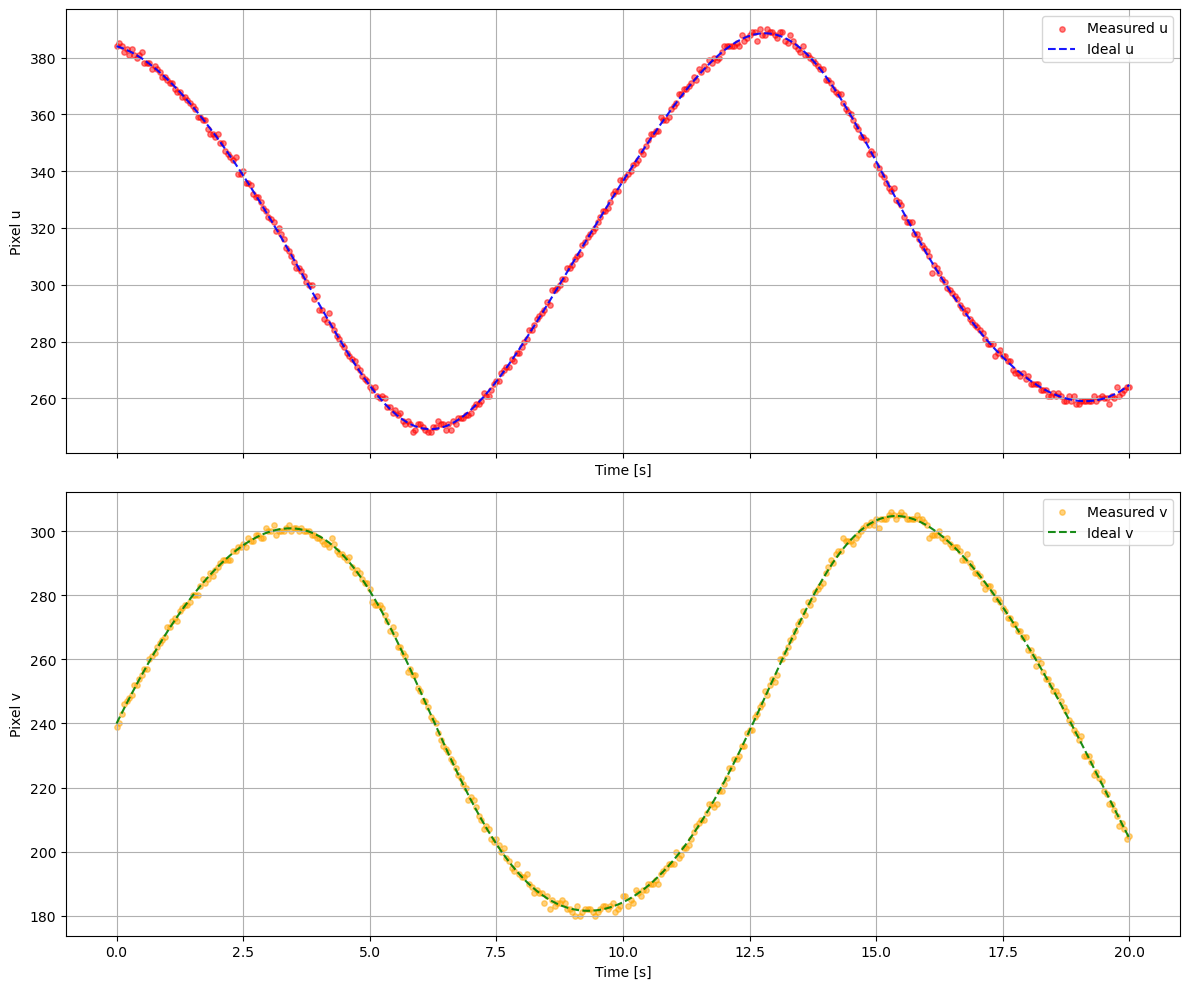

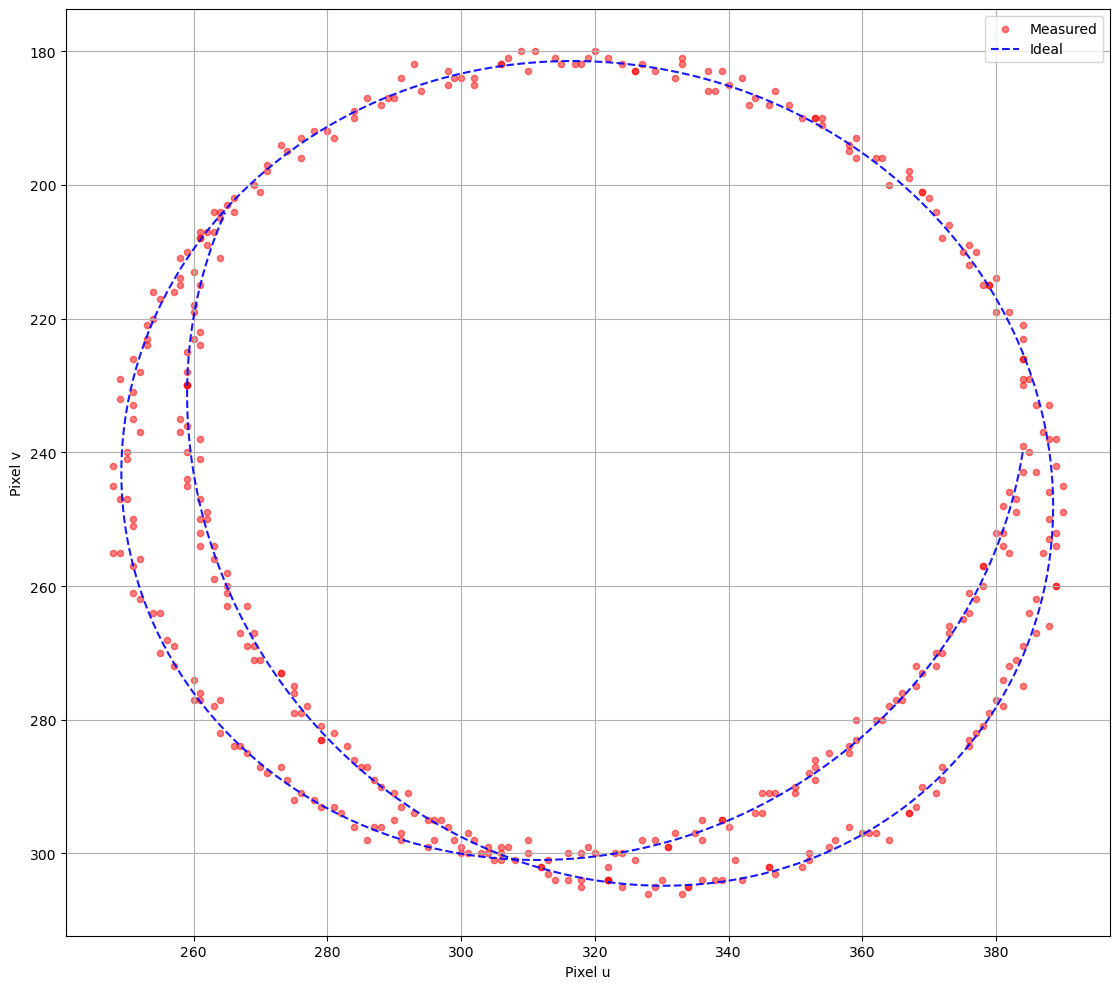

In [10]:
times = np.array([r.stamp for r in records])

ideal_u = np.array([
    r.ideal_uv[0] if r.ideal_uv is not None else np.nan for r in records
])

ideal_v = np.array([
    r.ideal_uv[1] if r.ideal_uv is not None else np.nan for r in records
])

meas_u = np.array([
    r.measurement.u if r.measurement is not None else np.nan for r in records
])

meas_v = np.array([
    r.measurement.v if r.measurement is not None else np.nan for r in records
])

def plot_single_coordinate(times, ideal, measured, label, ylabel, ax=None, ideal_color="blue", measured_color="red"):
    if ax is None:
        plt.figure(figsize=(12, 6))
        ax = plt.gca()

    ax.scatter(times, measured, label=f"Measured {label}", color=measured_color, s=15, alpha=0.5)
    ax.plot(times, ideal, label=f"Ideal {label}", color=ideal_color, linestyle="--", alpha=0.9)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)

def plot_trajectory(times, ideal_u, ideal_v, meas_u, meas_v, ax=None):
    if ax is None:
        plt.figure(figsize=(8, 8))
        ax = plt.gca()

    ax.scatter(meas_u, meas_v, label="Measured", color="red", s=20, alpha=0.5)
    ax.plot(ideal_u, ideal_v, label="Ideal", color="blue", linestyle="--", alpha=0.9)
    ax.set_xlabel("Pixel u")
    ax.set_ylabel("Pixel v")
    # invert y-axis to match image coordinates
    ax.invert_yaxis()
    ax.legend()
    ax.grid(True)
    ax.set_aspect('equal', adjustable='box')

fig, axs = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
plot_single_coordinate(times, ideal_u, meas_u, label="u", ylabel="Pixel u", ax=axs[0])
plot_single_coordinate(times, ideal_v, meas_v, label="v", ylabel="Pixel v", ax=axs[1], ideal_color="green", measured_color="orange")
plt.tight_layout()

fig, ax = plt.subplots(figsize=(12, 10))
plot_trajectory(times, ideal_u, ideal_v, meas_u, meas_v, ax=ax)
plt.tight_layout()

## Some test visualizations:

In [11]:
def set_axes_equal_3d(ax):
    """
    Make 3D plot axes have equal scale.
    This is important because otherwise orientations can look distorted.
    """
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])

    max_range = max(x_range, y_range, z_range)

    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)

    ax.set_xlim3d([x_middle - max_range / 2, x_middle + max_range / 2])
    ax.set_ylim3d([y_middle - max_range / 2, y_middle + max_range / 2])
    ax.set_zlim3d([z_middle - max_range / 2, z_middle + max_range / 2])


def pixel_to_camera_plane(
    camera: Camera,
    u: float,
    v: float,
    depth: float,
) -> np.ndarray:
    """
    Convert an image pixel coordinate (u, v) into a 3D point on the
    camera image plane at a chosen depth.

    The returned point is expressed in the camera optical frame.

    Camera convention:
        x: right
        y: down
        z: forward
    """
    cx, cy = camera.intrinsics.principal_point

    x = (u - cx) * depth / camera.intrinsics.fx
    y = (v - cy) * depth / camera.intrinsics.fy
    z = depth

    return np.array([x, y, z], dtype=float)


def plot_camera_pose_3d(
    camera: Camera,
    ax=None,
    axis_length: float = 1.0,
    frustum_depth: float = 2.0,
    show_frustum: bool = True,
    show_world_frame: bool = True,
    show_principal_point: bool = True,
    drone_position_world: np.ndarray | None = None,
    show_drone_projection: bool = True,
):
    """
    Plot the camera position, orientation, image plane, and optionally a drone
    and its projection onto the image plane.

    Camera convention:
        camera x-axis: right
        camera y-axis: down
        camera z-axis: forward
    """
    if ax is None:
        fig = plt.figure()
        ax = fig.add_subplot(111, projection="3d")

    position = camera.extrinsics.t_camera_to_world
    R_cw = camera.extrinsics.R_camera_to_world

    camera_x_world = R_cw @ np.array([1.0, 0.0, 0.0])
    camera_y_world = R_cw @ np.array([0.0, 1.0, 0.0])
    camera_z_world = R_cw @ np.array([0.0, 0.0, 1.0])

    # Camera origin.
    ax.scatter(position[0], position[1], position[2], s=50, color="k")
    #ax.text(position[0], position[1], position[2], f" {camera.name}")

    # Camera axes.
    ax.quiver(
        position[0], position[1], position[2],
        camera_x_world[0], camera_x_world[1], camera_x_world[2],
        length=axis_length,
        normalize=True,
        color="r",
        label="camera x/right",
    )

    ax.quiver(
        position[0], position[1], position[2],
        camera_y_world[0], camera_y_world[1], camera_y_world[2],
        length=axis_length,
        normalize=True,
        color="g",
        label="camera y/down",
    )

    ax.quiver(
        position[0], position[1], position[2],
        camera_z_world[0], camera_z_world[1], camera_z_world[2],
        length=axis_length,
        normalize=True,
        color="b",
        label="camera z/forward",
    )

    # World frame axes.
    if show_world_frame:
        origin = np.array([0.0, 0.0, 0.0])

        ax.quiver(
            origin[0], origin[1], origin[2],
            1.0, 0.0, 0.0,
            length=axis_length,
            normalize=True,
            color="r",
            linestyle="--",
        )

        ax.quiver(
            origin[0], origin[1], origin[2],
            0.0, 1.0, 0.0,
            length=axis_length,
            normalize=True,
            color="g",
            linestyle="--",
        )

        ax.quiver(
            origin[0], origin[1], origin[2],
            0.0, 0.0, 1.0,
            length=axis_length,
            normalize=True,
            color="b",
            linestyle="--",
        )

        # ax.text(axis_length, 0.0, 0.0, "world x")
        # ax.text(0.0, axis_length, 0.0, "world y")
        # ax.text(0.0, 0.0, axis_length, "world z")

    # Image plane / frustum.
    if show_frustum:
        w = camera.intrinsics.width_px
        h = camera.intrinsics.height_px
        z = frustum_depth

        corners_camera = np.array([
            pixel_to_camera_plane(camera, 0.0, 0.0, z),
            pixel_to_camera_plane(camera, w,   0.0, z),
            pixel_to_camera_plane(camera, w,   h,   z),
            pixel_to_camera_plane(camera, 0.0, h,   z),
        ])

        corners_world = np.array([
            position + R_cw @ corner
            for corner in corners_camera
        ])

        # Rays from camera center to image corners.
        for corner_world in corners_world:
            ax.plot(
                [position[0], corner_world[0]],
                [position[1], corner_world[1]],
                [position[2], corner_world[2]],
                color="gray",
                linestyle="--",
            )

        # Image plane rectangle.
        closed_corners = np.vstack([corners_world, corners_world[0]])
        ax.plot(
            closed_corners[:, 0],
            closed_corners[:, 1],
            closed_corners[:, 2],
            color="gray",
        )

        # Lightly fill the image plane.
        ax.plot_trisurf(
            corners_world[:, 0],
            corners_world[:, 1],
            corners_world[:, 2],
            triangles=[[0, 1, 2], [0, 2, 3]],
            alpha=0.12,
            color="gray",
        )

    # Principal point.
    if show_principal_point:
        principal_point_camera = pixel_to_camera_plane(
            camera,
            *camera.intrinsics.principal_point,
            depth=frustum_depth,
        )

        principal_point_world = position + R_cw @ principal_point_camera

        ax.scatter(
            principal_point_world[0],
            principal_point_world[1],
            principal_point_world[2],
            s=50,
            color="b",
            label="principal point",
        )

        # ax.text(
        #     principal_point_world[0],
        #     principal_point_world[1],
        #     principal_point_world[2],
        #     " principal point",
        # )

    # Drone and its projection.
    if drone_position_world is not None:
        drone_position_world = np.asarray(drone_position_world, dtype=float).reshape(3)

        ax.scatter(
            drone_position_world[0],
            drone_position_world[1],
            drone_position_world[2],
            s=80,
            color="k",
            marker="o",
            label="drone",
        )

        # ax.text(
        #     drone_position_world[0],
        #     drone_position_world[1],
        #     drone_position_world[2],
        #     " drone",
        # )

        if show_drone_projection:
            point_camera = camera.world_to_camera(drone_position_world)
            projected_pixel = camera.project_camera_point(point_camera)

            # Ray from camera to actual drone position.
            ax.plot(
                [position[0], drone_position_world[0]],
                [position[1], drone_position_world[1]],
                [position[2], drone_position_world[2]],
                color="k",
                linestyle=":",
            )

            if projected_pixel is not None:
                u, v = projected_pixel

                projection_camera = pixel_to_camera_plane(
                    camera,
                    u,
                    v,
                    depth=frustum_depth,
                )

                projection_world = position + R_cw @ projection_camera

                ax.scatter(
                    projection_world[0],
                    projection_world[1],
                    projection_world[2],
                    s=80,
                    color="m",
                    marker="x",
                    label="drone projection",
                )

                ax.plot(
                    [drone_position_world[0], projection_world[0]],
                    [drone_position_world[1], projection_world[1]],
                    [drone_position_world[2], projection_world[2]],
                    color="m",
                    linestyle="--",
                )

                # ax.text(
                #     projection_world[0],
                #     projection_world[1],
                #     projection_world[2],
                #     f" projection ({u:.1f}, {v:.1f})",
                # )

    ax.set_xlabel("world x")
    ax.set_ylabel("world y")
    ax.set_zlabel("world z")
    ax.set_title("Camera pose, image plane, and drone projection")

    set_axes_equal_3d(ax)

    return ax

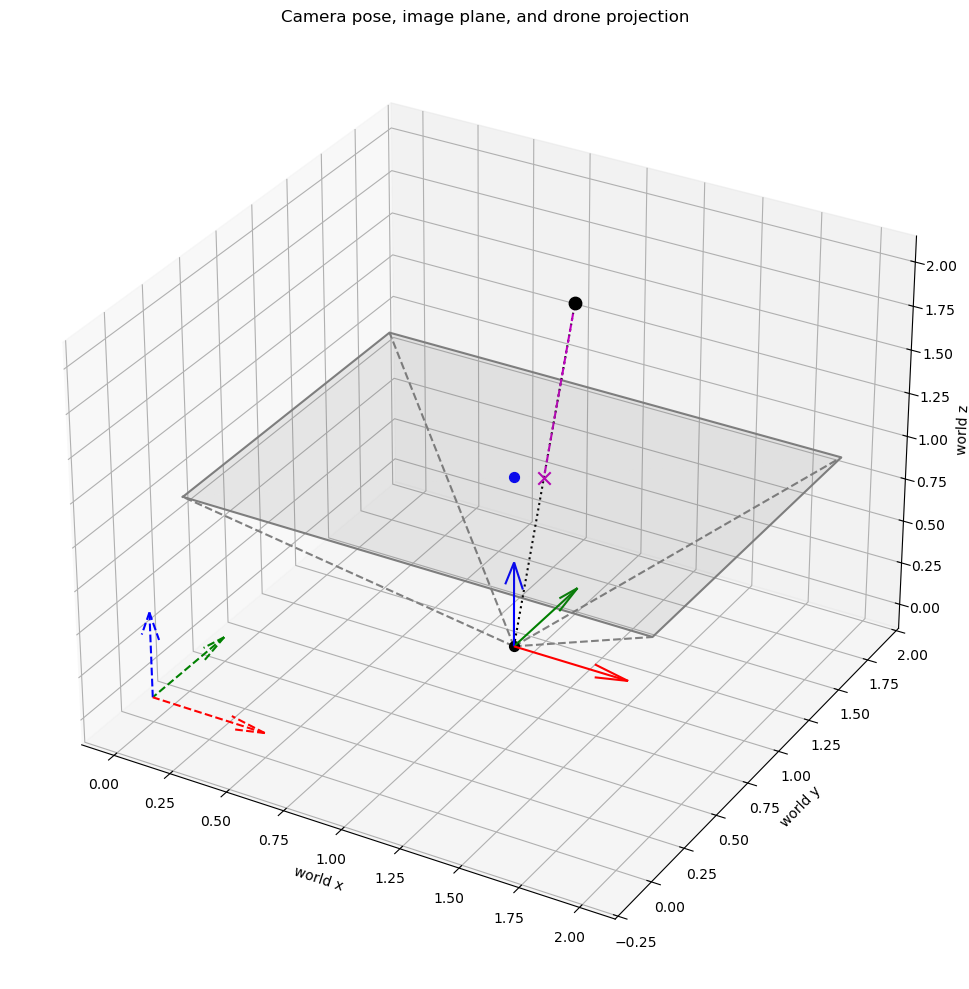

In [12]:
rot_angle_deg = 0

rot_axis = np.array([0, 1, 0])

# turn the axis into a unit vector
rot_axis = rot_axis / np.linalg.norm(rot_axis)

# compute the quaternion representing the rotation
rot_angle_rad = np.deg2rad(rot_angle_deg)

quat = normalize_quaternion(np.array([
    rot_axis[0] * np.sin(rot_angle_rad / 2),
    rot_axis[1] * np.sin(rot_angle_rad / 2),
    rot_axis[2] * np.sin(rot_angle_rad / 2),
    np.cos(rot_angle_rad / 2)
]))

camera = Camera(
    name="camera_1",
    frame_id="camera_1_optical_frame",
    intrinsics=CameraIntrinsics(
        width_px=640,
        height_px=480,
        fx=320.0,
        fy=320.0,
    ),
    extrinsics=CameraExtrinsics(
        position=np.array([1.0, 1.0, 0.0]),
        orientation=quat,
    ),
    noise_model=CameraNoiseModel(
        pixel_noise_std_u=0.0,
        pixel_noise_std_v=0.0,
        discretize=False,
    ),
)

drone_position_world = np.array([1.2, 1.1, 2.0])

fig, ax = plt.subplots(
    subplot_kw={"projection": "3d"},
    figsize=(10, 10),
)

plot_camera_pose_3d(
    camera,
    ax=ax,
    axis_length=0.5,
    frustum_depth=1.0,
    show_frustum=True,
    show_world_frame=True,
    show_principal_point=True,
    drone_position_world=drone_position_world,
    show_drone_projection=True,
)

fig.tight_layout()
plt.show()